# Get Bio-ARGO data
**Author:** Eli Holmes (NOAA)</br>
Last updated: November 21, 2026

>📘 Learning Objectives
>
> 1. Get [Argo data](https://www.aoml.noaa.gov/argo) using the [argopy](https://pypi.org/project/argopy/) Python package
> 2. Learn the basic format of the data grouped into platform and cycles
> 3. Learn how to filter to just surface data
> 4. Learn how to get data in batches

Biogeochemical Argo (“Bio-Argo” or BGC-Argo) floats are autonomous profiling instruments that drift with ocean currents and periodically dive from the surface to depths of 1,000–2,000 meters, collecting a vertical profile of physical and biogeochemical properties. These floats are all over the world's oceans and the data are freely available via the Argo global data assembly centers (GDACs) [Video on the Argo system](https://youtu.be/IixnxfysYAE?si=5xcPe6wa3LoWqUL3).

Each float has a unique PLATFORM_NUMBER, and every time it dives and returns to the surface it produces a new profile, identified by its CYCLE_NUMBER. A single float may produce hundreds of profiles over several years. Bio-Argo floats carry optical, chemical, and physical sensors that measure variables such as chlorophyll-a (CHLA), temperature (TEMP), salinity (PSAL), pressure (PRES, which is used as depth), dissolved oxygen (DOXY), and nitrate (NITRATE). These data are distributed in a consistent, profile-based format: each profile (platform+cycle) contains measurements at multiple depths, along with time, latitude, longitude, and quality-control flags. To use these data for surface-matching with satellite products, we will extract the shallow measurements from each profile (pressure is less than 20dbar or 10dbar). We will use the [argopy](https://pypi.org/project/argopy/) package to download Argo data from the [Coriolis Argo Global Assembly Center](https://coriolis-93c5db.gitlab-pages.ifremer.fr/).

![](Supporting_files/argo_float_cycle.png)

## Workflow

Here is our basic workflow.

1. Use `argopy` to fetch data for Bio-Argo profiles in a given region and time
3. For each profile, save one point, the shallowest reading.
4. Process the globe in monthly chunks to not overload the ERDDAP server and save the monthly shallow points to a parquet file.

In [1]:
!pip -q install argopy

## Step 1. Get some data

In this first step we’ll grab some in-situ data from Bio-Argo floats. We use `argopy`’s `ArgoDataFetcher` function to set up a datafetcher object with the information on what dataset (`ds` arg), where (`src` arg) and what parameters. We can access data by a specific buoy (platform), cycle (one descending/ascending cycle of a float), or by region (any data in that region, depth, time). We will use region. Once we set up our datafetcher object, we request the data using a method like `to_xarray()` or `to_dataframe()` to get the data and return in a specific form. We will use `to_xarray()` because the processing by buoy/cycle to get the shallowest points will be easier using xarray.

The code below requests only chlorophyll (CHLA) and pressure (PRES) for March 2024 in our chosen region and returns the result as an xarray Dataset that we can later save as a parquet file.

We are going to use `mode="expert"` and use `CHLA_ADJUSTED`. 

In [2]:
# get some data
from argopy import DataFetcher as ArgoDataFetcher
# specify the data set and what source
fetcher = ArgoDataFetcher(
    ds="bgc",
    src="erddap",
    params=["CHLA", "PRES"], # both these need to be present
    mode="expert"
)
# specify that we want to access data in a region; a NW Atlantic box
# lon_min, lon_max, lat_min, lat_max, depth_min, depth_max, time_min, time_max
region = [-70, -40, 20, 60, 0, 1000, "2024-03-01", "2024-04-01"]
fetcher = fetcher.region(region)
fetcher

<datafetcher.erddap>
⭐ Name: Ifremer erddap Argo BGC data fetcher for a space/time region
🗺  Domain: [x=-70.00/-40.00; y=20.00/60.00; z=0.0/1000.0; t=2024-03-01/2024-04-01]
🔗 API: https://erddap.ifremer.fr/erddap
📗 Parameters: ['CHLA', 'PRES', 'TEMP', 'PSAL']
📕 BGC 'must be measured' parameters: []
🏄 User mode: expert
🟢 Dataset: bgc-s
🌥  Performances: cache=False, parallel=False

In [3]:
# Get the data using the to_xarray() method
ds_na = fetcher.to_xarray()

/srv/conda/envs/notebook/lib/python3.13/site-packages/argopy/stores/index/implementations/pandas/search_engine.py:59: UserWarning: Searching a large amount of Argo floats with the Pandas backend is quite slow. We strongly recommend to install Pyarrow to improve performances ! Pyarrow is about 10 times faster than Pandas for this use-case.
  warnings.warn("Searching a large amount of Argo floats with the Pandas backend is quite slow. We strongly recommend to install Pyarrow to improve performances ! Pyarrow is about 10 times faster than Pandas for this use-case.")


In [4]:
ds_na

<xarray.Dataset> Size: 18MB
Dimensions:                (N_POINTS: 86163)
Coordinates:
  * N_POINTS               (N_POINTS) int64 689kB 0 1 2 3 ... 86160 86161 86162
    LATITUDE               (N_POINTS) float64 689kB 27.53 27.53 ... 55.55 55.55
    LONGITUDE              (N_POINTS) float64 689kB -50.32 -50.32 ... -54.36
    TIME                   (N_POINTS) datetime64[ns] 689kB 2024-03-01T05:16:5...
Data variables: (12/30)
    CHLA                   (N_POINTS) float32 345kB nan nan 0.0504 ... nan nan
    CHLA_ADJUSTED          (N_POINTS) float32 345kB 1e+05 1e+05 ... nan nan
    CHLA_ADJUSTED_ERROR    (N_POINTS) float32 345kB 1e+05 1e+05 ... nan nan
    CHLA_ADJUSTED_QC       (N_POINTS) int64 689kB 9 9 1 9 9 1 9 ... 9 9 9 9 9 9
    CHLA_DATA_MODE         (N_POINTS) <U1 345kB 'A' 'A' 'A' 'A' ... '' '' '' ''
    CHLA_QC                (N_POINTS) int64 689kB 9 9 3 9 9 3 9 ... 9 9 9 9 9 9
    ...                     ...
    TEMP_ADJUSTED          (N_POINTS) float32 345kB 22.8 22.8 ... 3.478 3.477
    TEMP_ADJUSTED_ERROR    (N_POINTS) float32 345kB 0.002 0.002 ... 0.002 0.002
    TEMP_ADJUSTED_QC       (N_POINTS) int64 689kB 1 1 8 1 1 8 1 ... 8 1 8 8 1 8
    TEMP_DATA_MODE         (N_POINTS) <U1 345kB 'D' 'D' 'D' 'D' ... 'D' 'D' 'D'
    TEMP_QC                (N_POINTS) int64 689kB 1 1 8 1 1 8 1 ... 8 1 8 8 1 8
    TIME_QC                (N_POINTS) int64 689kB 1 1 1 1 1 1 1 ... 1 1 1 1 1 1
Attributes:
    DATA_ID:              ARGO-BGC
    DOI:                  http://doi.org/10.17882/42182
    Fetched_from:         erddap.ifremer.fr
    Fetched_by:           jovyan
    Fetched_date:         2026/11/22
    Fetched_constraints:  [x=-70.00/-40.00; y=20.00/60.00; z=0.0/1000.0; t=20...
    Fetched_uri:          https://erddap.ifremer.fr/erddap/tabledap/ArgoFloat...

In [5]:
# How many row in our dataframe?
df = ds_na.to_dataframe().reset_index()
df.shape[0]

86163

### Plot the data

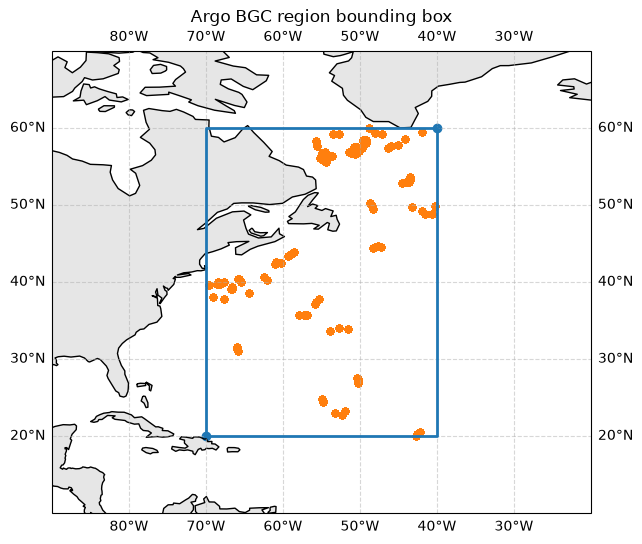

In [6]:
# plot the data; includes all buoys and all depths during each cycle
lon_min, lon_max, lat_min, lat_max = region[:4]
ds = ds_na

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature


# Corners of the box (closed loop)
lons = [lon_min, lon_max, lon_max, lon_min, lon_min]
lats = [lat_min, lat_min, lat_max, lat_max, lat_min]

proj = ccrs.PlateCarree()

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=proj)

# Show a bit more context than just the box
ax.set_extent([lon_min - 20, lon_max + 20, lat_min - 10, lat_max + 10], crs=proj)

# Add coastlines and land
ax.coastlines(resolution="110m")
ax.add_feature(cfeature.LAND, facecolor="0.9")
ax.add_feature(cfeature.OCEAN, facecolor="white")
ax.gridlines(draw_labels=True, linestyle="--", alpha=0.5)

# Plot the bounding box
ax.plot(lons, lats, transform=proj, linewidth=2)
ax.scatter([lon_min, lon_max], [lat_min, lat_max], transform=proj)

# Add the Argo points from ds
ax.scatter(
    ds["LONGITUDE"].values,
    ds["LATITUDE"].values,
    s=20,
    marker="o",
    transform=proj,
)

ax.set_title("Argo BGC region bounding box")

plt.show()



### Profiles: a descending/ascending cycle

The data for each buoy are organized into cycles which is data collected on one descending/ascending cycle. Depending how the buoy is set up to record data, it might record only on the descending or ascending part of the cycle. The data that the ocean color satellites measure is just the surface. Even if there is high CHLA in deep water, the satellite does not "see" that. Thus we need to filter our cycle data from just the upper layer (< 20 m or so).

**For the CHLA-Z tables we keep only the ascending profile** (`DIRECTION == "A"`). About 5% of cycles also sample on descent, but only 12% of those descending profiles have any CHLA level that passes QC, and the descent is a median 5 days and 10 km away from the ascent. Pooling the two (as the 2025 version did) attached the descent's time and position to data that mostly came from the ascent.

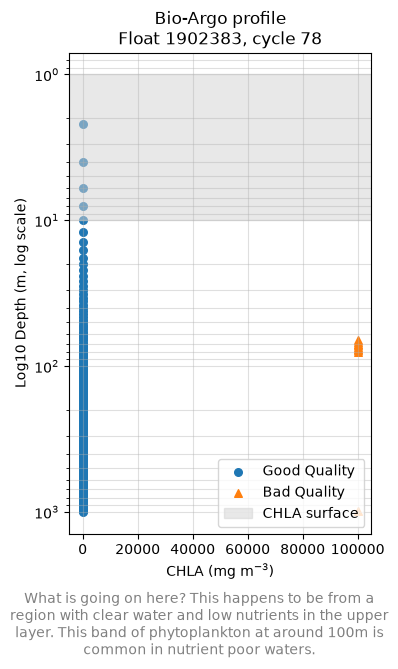

In [7]:
import numpy as np
import matplotlib.pyplot as plt

ds = ds_na  # just to keep the name short

# Unique platform numbers in the dataset
platforms = np.unique(ds["PLATFORM_NUMBER"].values)
plat = int(platforms[0])

# All cycles for that platform
cycles = ds["CYCLE_NUMBER"].where(ds["PLATFORM_NUMBER"] == plat, drop=True)
cycles = np.unique(cycles.values)
cyc = int(cycles[0])

# Select all points belonging to that profile
prof = ds.where(
    (ds["PLATFORM_NUMBER"] == plat) & (ds["CYCLE_NUMBER"] == cyc),
    drop=True
)

chl   = prof["CHLA_ADJUSTED"]
pres  = prof["PRES"]
qc = prof["CHLA_ADJUSTED_QC"]   

# Depth in meters ~ pressure in dbar
depth = pres
depth_plot = depth.clip(min=1)  # avoid 0 for log scale

# Masks for ascending/descending
good_mask =  qc.isin([1, 2, 5, 8])
bad_mask = ~good_mask

fig, ax = plt.subplots(figsize=(4, 6))

# Plot descending profile
ax.scatter(
    chl.where(good_mask),
    depth_plot.where(good_mask),
    label="Good Quality",
    s=30,
)

# Plot ascending profile
ax.scatter(
    chl.where(bad_mask),
    depth_plot.where(bad_mask),
    label="Bad Quality",
    s=30,
    marker="^",
)

# Add a shaded layer representing what is often designated as CHLA surface (e.g. 0–10 m)
z_sat = 10  # meters; adjust to taste for your explanation
ax.axhspan(1, z_sat, color="lightgrey", alpha=0.5,
           label="CHLA surface")

# Log scale on depth axis, surface at top
ax.set_yscale("log")
ax.invert_yaxis()

ax.set_xlabel("CHLA (mg m$^{-3}$)")
ax.set_ylabel("Log10 Depth (m, log scale)")
ax.set_title(f"Bio-Argo profile\nFloat {plat}, cycle {cyc}")
ax.grid(True, which="both", alpha=0.4)
ax.legend(loc="lower right")
plt.figtext(0.5, -0.1, "What is going on here? This happens to be from a region with clear water and low nutrients in the upper layer. This band of phytoplankton at around 100m is common in nutrient poor waters.",
            wrap=True, horizontalalignment='center', fontsize=10, color='gray')

# Adjust the bottom margin to make space for the annotation if necessary
#fig.subplots_adjust(bottom=0.25) # Increase bottom margin if annotation is cut off

plt.tight_layout()
plt.show()


## Step 2 Compute point estimates

We will compute two point estimates from the profiles of CHLA: 1) the surface average from 0 to 10m and 2) binned averages from 0 to 200m in bins 10m wide. We use `CHLA_ADJUSTED`, keep only levels with `CHLA_ADJUSTED_QC` in {1, 2, 5, 8}, and do this **before** averaging. Only ascending profiles are used. Note the bins follow `average_profile()`: a level at pressure `PRES` goes in bin A–B when A < PRES <= B.

### Create functions to make these calculations from a profile

* `average_profile` takes the depth (`PRES`) and variable (`CHLA`) and gets the average over a depth range.
* `summarize_profile_binned` takes a filtered dataframe with just one profile (PLATFORM_NUMBER/CYCLE_NUMBER) and gives means for binned depths like 0 to 10m.

In [8]:
# average over a depth band
def average_profile(depth, var, z_min=0.0, z_max=None):
    """
    Average a var profile over a depth range.

    Parameters
    ----------
    depth : array-like
        1D array of depth or pressure (m or dbar ≈ m), increasing downward.
    var : array-like
        1D array of variable same shape as `depth`.
    z_min : float, optional
        Lower bound of depth (e.g. 0 for surface), in same units as depth.
    z_max : float or None, optional
        Upper bound of depth. If None, use max(depth).

    Returns
    -------
    Mean of var [z_min, z_max]. Returns np.nan if insufficient data.
    Number of data points in [z_min, z_max].
    """
    depth = np.asarray(depth, dtype=float)
    var   = np.asarray(var,   dtype=float)

    # Mask out NaNs
    m = np.isfinite(depth) & np.isfinite(var)
    depth = depth[m]
    var   = var[m]

    if depth.size < 1:
        return np.nan, 0

    # Set z_max if not provided
    if z_max is None:
        z_max = depth.max()

    # Subset to [z_min, z_max]
    sel = (depth > z_min) & (depth <= z_max)
    depth = depth[sel]
    var   = var[sel]

    if depth.size < 1:
        return np.nan, 0

    # Mean
    return np.mean(var), len(var)

In [9]:
# function to create our metrics for a platform/cycle group
import numpy as np
import pandas as pd

def summarize_profile_binned(group, var, depth_bins=None, include_meta=False, out_name=None):
    """
    Summarize a single Bio-Argo profile into depth-binned CHL means and one integrated bin.

    Parameters
    ----------
    group : dataframe
        dataframe with PRES, TIME, LATITUDE, LONGITUDE, var. Expected to be from
        filtering a Argo dataframe by PLATFORM_NUMBER and CYCLE_NUMBER
    var : str
        name of variable like `CHLA`.
    depth_bins : list, optional
        list of bins. Default is 0,10,...,200
    include_meta : Bool, optional
        whether to include TIME, LATITUDE, LONGITUDE in the returned dataframe
    out_name : str, optional
        base name to use for the output columns (e.g. `CHLA`). Defaults to `var`.
        Use this to read data from `CHLA_ADJUSTED` but label columns as `CHLA`.

    Returns
    -------
    Returns pd.Series with one row with CHL in each depth bin + metadata (if include_meta=True)
    """
    depth_bins = np.arange(0, 210, 10)  # 0,10,...,200

    if out_name is None:
        out_name = var

    z = group["PRES"].values
    c = group[var].values

    out = {}

    if include_meta:# metadata
        out["TIME"]      = group["TIME"].iloc[0]
        out["LATITUDE"]  = group["LATITUDE"].iloc[0]
        out["LONGITUDE"] = group["LONGITUDE"].iloc[0]

    # depth-binned means
    for z0, z1 in zip(depth_bins[:-1], depth_bins[1:]):
        col1 = f"{out_name}_{int(z0)}_{int(z1)}"
        col2 = f"{out_name}_{int(z0)}_{int(z1)}_N"
        out[col1], out[col2] = average_profile(z, c, z_min=z0, z_max=z1)

    return pd.Series(out)

The `summarize_profile_binned` will return the depth binned averages for each profile.

In [10]:
# convert the xarray dataset from Argo to dataframe
df = ds_na.to_dataframe().reset_index()

# Ascending profiles only, then QC, before any averaging
df = df[df["DIRECTION"] == "A"]
df_qc = df[df["CHLA_ADJUSTED_QC"].isin([1, 2, 5, 8])]

# Get the binned averages and add on some metadata
df_points = (
    df_qc
    .groupby(["PLATFORM_NUMBER", "CYCLE_NUMBER"], as_index=False)
    .apply(summarize_profile_binned, var="CHLA_ADJUSTED", out_name="CHLA", include_meta=True, include_groups=False)   # default 0–200m in 10m bins
    .reset_index(drop=True)
)

In [11]:
df_points.head()

,PLATFORM_NUMBER,CYCLE_NUMBER,TIME,LATITUDE,LONGITUDE,CHLA_0_10,CHLA_0_10_N,CHLA_10_20,CHLA_10_20_N,CHLA_20_30,...,CHLA_150_160,CHLA_150_160_N,CHLA_160_170,CHLA_160_170_N,CHLA_170_180,CHLA_170_180_N,CHLA_180_190,CHLA_180_190_N,CHLA_190_200,CHLA_190_200_N
0,1902383,78,2024-03-02 16:13:24.002000128,23.0209,-53.2220,0.018227,5,0.019037,5,0.021672,...,0.165353,5,0.129483,5,0.069701,5,0.053894,5,0.031804,5
1,1902383,79,2024-03-12 15:19:00.002000128,22.7279,-52.3932,0.014318,4,0.017251,6,0.016480,...,0.160686,5,0.121467,5,0.073801,5,0.053085,5,0.032972,5
2,1902383,80,2024-03-22 15:28:33.002000128,23.2649,-52.0005,0.013061,5,0.029955,5,0.019899,...,0.082650,5,0.073599,5,0.079633,5,0.058113,5,0.035386,5
3,1902384,79,2024-03-08 20:58:18.002000128,20.0154,-42.7101,0.036876,5,0.038240,5,0.040190,...,0.184062,5,0.151896,5,0.101014,5,0.057930,5,0.038630,5
4,1902384,80,2024-03-18 20:31:41.002000128,20.3018,-42.5525,0.022774,6,0.024399,5,0.027518,...,0.250930,5,0.155795,5,0.092436,5,0.065143,5,0.046623,5


In [12]:
len(df_points)

60

## Summary

Now you can query the Bio-Argo ERDDAP server and get Argo profiles for any region and time frame. You can filter the data by quality and get averages for different depths. 

Stop here is you just need to know how to get Bio-Argo data. In the next section, I show how I queried for the whole globe and assembled into monthly 10-20Mb netcdfs which I process into a 2Mb dataframe with rows for each profile (a single descend/ascend cycle for a buoy) with the binned CHLA averages. This dataframe is small enough to keep on GitHub with the tutorials. This has all profiles, CHLA data were not filtered by quality and CHLA for many depth bins, including surface, may be missing. You can load and plot this file as

In [13]:
# Load data from GitHub
import pandas as pd
url = "https://raw.githubusercontent.com/fish-pace/fish-pace-datasets/main/datasets/chla_z/data/CHLA_argo_profiles.parquet"
df = pd.read_parquet(url)
print(f"\nNumber of profiles in the dataset {len(df)}\n")
df.head()


Number of profiles in the dataset 15833



,profile_id,PLATFORM_NUMBER,CYCLE_NUMBER,TIME,LATITUDE,LONGITUDE,CHLA_0_10,CHLA_0_10_N,CHLA_10_20,CHLA_10_20_N,...,CHLA_150_160,CHLA_150_160_N,CHLA_160_170,CHLA_160_170_N,CHLA_170_180,CHLA_170_180_N,CHLA_180_190,CHLA_180_190_N,CHLA_190_200,CHLA_190_200_N
0,1902304_0155,1902304,155,2024-03-01 21:23:16.002000128,54.6582,-19.2434,0.150386,4,0.158043,5,...,0.157366,5,0.158550,5,0.154490,5,0.153305,5,0.154151,5
1,1902304_0156,1902304,156,2024-03-11 20:45:53.002000128,54.9187,-18.9609,0.155674,4,0.156858,5,...,0.131986,5,0.135201,5,0.135539,5,0.136385,5,0.134524,5
2,1902304_0157,1902304,157,2024-03-21 21:21:39.002000128,55.2967,-18.8331,0.195647,4,0.202542,5,...,0.202204,5,0.200004,5,0.198820,5,0.194590,5,0.198651,5
3,1902304_0158,1902304,158,2024-03-31 21:31:53.002000128,55.7268,-18.8653,0.190783,4,0.193575,5,...,0.155336,5,0.153982,5,0.143492,5,0.135201,5,0.143830,5
4,1902380_0079,1902380,79,2024-03-07 18:01:17.002000128,17.6665,-46.0155,0.008062,4,0.009940,5,...,0.105501,5,0.066193,5,0.053091,5,0.043657,5,0.031253,5


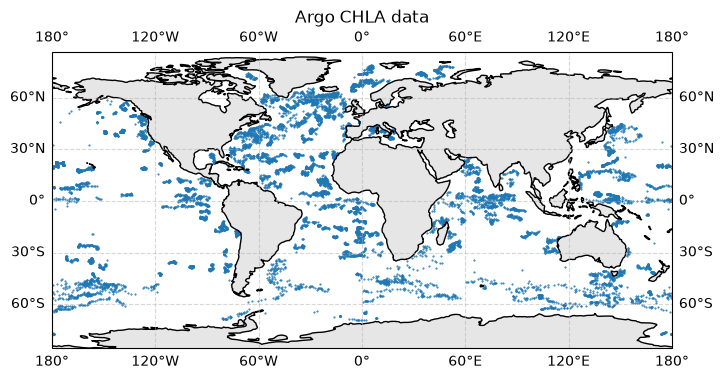

In [14]:
# plot the data
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

proj = ccrs.PlateCarree()

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=proj)

# Add coastlines and land
ax.coastlines(resolution="110m")
ax.add_feature(cfeature.LAND, facecolor="0.9")
ax.add_feature(cfeature.OCEAN, facecolor="white")
ax.gridlines(draw_labels=True, linestyle="--", alpha=0.5)

df_clean = df.dropna(subset=["CHLA_0_10"])

# Add the Argo points from df
ax.scatter(
    df_clean["LONGITUDE"].values,
    df_clean["LATITUDE"].values,
    s=1,
    marker=".",
    transform=proj,
)

ax.set_title("Argo CHLA data")

plt.show()

Each dot is a profile (descend/ascend cycle for one buoy). Some regions are better represented that others.

---

**If you want to see how I assembled the global file, read below.**

# Process data from the whole globe

I will show 2 workflows. The first one gets Argo data and processes that into a dataframe with CHLA binned averages for each profile (descend/ascend cycle for a buoy). The dataframe has one row per Argo profile. Then these dataframes are assembled together into one parquet file for the whole globe. This problem with this is that if you change your mind regarding how to summarize the Argo data, then you have to query the Argo ERDDAP server again. If you are doing a lot of experimentation, then you keep hitting their server over and over (slow and excessive use of their server).  So in the second workflow, I saved 10-20Mb netcdfs for all Bio-Argo data for a month and then worked with that as I experimented with how to summarize the profile data (measurements at each depth).

## Workflow 1: Process into profile summaries directly

There are 3 steps, which take in total about 4 hours. 

1. Get profile summaries for a region and month. To do this create the function `get_bgc_profile()`. This will fetch profile Bio-Argo data for a region and month and save as parquet. Returns dataframe with one row per profile (a descend/ascend cycle for a buoy) with the whole CHLA binned profile (averages for different depth bins). Uses our `summarize_profile_binned()` function from above.
2. A for loop to work through the whole globe and save the monthly parquet files. This is the step that takes 4 hrs.
3. Merge these files altogether into one file to put on GitHub.

### A function to get one month `get_bgc_profile()`

Get a month for a region. Return a dataframe of the shallow points only. The function allows us to get multiple possible variables like CHLA, DOXY, NITRATE, BBP770, TEMP and PSAL. However if we pass in multiple variables then all must be present, so to maximize the data only pass in one varible at a time unless you need paired measurements.

In [15]:
# get_bgc_profile() function
from pathlib import Path

import numpy as np
import pandas as pd
from argopy import DataFetcher as ArgoDataFetcher


def get_bgc_profile(reg, mon, data_dir="data", vars=None, save=False, mode="standard"):
    """
    Fetch profile Bio-Argo data for a region and month and (optionally) save as parquet.
    Returns dataframe with one row per profile (a descend/ascend cycle for a buoy)
    with the whole CHLA binned profile (averages for different depth bins).

    Parameters
    ----------
    reg : sequence
        [lon_min, lon_max, lat_min, lat_max, depth_min, depth_max]
        (same as argopy region, but without time bounds).
    mon : str or datetime-like
        Month to fetch, e.g. "2024-03" or "2024-03-01".
    data_dir : str, optional
        Directory where the parquet file will be saved.
    vars : list of str, optional
        Bio-Argo variables to fetch and surface-average (e.g. ["CHLA", "BBP700", "DOXY"]).
        Defaults to ["CHLA"].
    save : bool, optional
        If True, save a parquet file and return (df_surf, path).
        If False, just return (df_surf, None).

    Returns
    -------
    df_surf : pandas.DataFrame
        Near-surface samples (one row per profile) with requested variables.
    out_path : str or None
        Path to the saved parquet file, or None if save=False.
    """
    if vars is None:
        vars = ["CHLA"]  # default behaviour

    # Required base columns in the data from Bio-Argo
    base_cols = [
        "PLATFORM_NUMBER", "CYCLE_NUMBER",
        "TIME", "LATITUDE", "LONGITUDE", "PRES",
    ]

    # De-duplicate and drop any that are base columns (e.g. PRES)
    extra_vars_raw = list(dict.fromkeys(vars))
    extra_vars = [v for v in extra_vars_raw if v not in base_cols]

    # Output base name for each source var: strip a trailing/infix '_ADJUSTED'
    # so CHLA_ADJUSTED is stored in CHLA_* columns.
    def out_name_for(v):
        return v.replace("_ADJUSTED", "")

    def extra_cols(var):
        depth_bins = np.arange(0, 210, 10)  # 0,10,...,200
        cols = []
        for v in var:
            name = out_name_for(v)
            cols.append(f"{name}_INT_150")
            for z0, z1 in zip(depth_bins[:-1], depth_bins[1:]):
                cols.append(f"{name}_{int(z0)}_{int(z1)}")
                cols.append(f"{name}_{int(z0)}_{int(z1)}_N")
        return cols
    # column names of the metrics, like CHLA_0_10 and CHLA_0_10_N
    var_metric_cols = extra_cols(extra_vars)

    # Columns that we need for processing the argo data
    argo_cols = base_cols + extra_vars
    # Final schema for the output DataFrame: base - PRES + colnames of points (like CHLA_INT_150)
    final_cols = base_cols + var_metric_cols 
    final_cols.remove("PRES");

    lon_min, lon_max, lat_min, lat_max, z_min, z_max = reg

    # Compute start/end of the month
    mon_start = pd.to_datetime(mon).to_period("M").start_time
    mon_end = (mon_start + pd.offsets.MonthBegin(1))

    region = [
        lon_min, lon_max,
        lat_min, lat_max,
        z_min, z_max,
        mon_start.strftime("%Y-%m-%d"),
        mon_end.strftime("%Y-%m-%d"),
    ]

    # STEP 1: Get data for region + month
    # We always request PRES, plus user extras (not TEMP/PSAL unless user asked).
    # argopy's `params` only accepts base names (e.g. CHLA, not CHLA_ADJUSTED),
    # so request the base variable; in expert mode the returned dataset includes
    # both CHLA and CHLA_ADJUSTED and we read the requested one below.
    def base_var_for(v):
        return v.replace("_ADJUSTED", "")
    param_vars = list(dict.fromkeys([base_var_for(v) for v in extra_vars] + ["PRES"]))

    fetcher = ArgoDataFetcher(
        ds="bgc",
        src="erddap",
        params=param_vars,
        mode=mode
    )

    try:
        ds = fetcher.region(region).to_xarray()
    except Exception as exc:
        print(f"No data for region={reg}, month={mon}: {exc}")
        # Return empty frame with full schema
        return pd.DataFrame(columns=final_cols), None

    # Bail if argopy returned an empty ds
    if "N_POINTS" in ds.sizes and ds.sizes["N_POINTS"] == 0:
        print(f"No data rows (N_POINTS=0) for region={reg}, month={mon}")
        return pd.DataFrame(columns=final_cols), None
    
    # Also guard against “all dims zero”
    if all(size == 0 for size in ds.sizes.values()):
        print(f"No data rows (all dims zero) for region={reg}, month={mon}")
        return pd.DataFrame(columns=final_cols), None    
        
    # STEP 2: Compute point metrics
    ds_vars = set(ds.data_vars) | set(ds.coords)

    # We only select columns that exist, but we *remember* full schema in argo_cols
    qc_cols = [f"{v}_QC" for v in extra_vars if f"{v}_QC" in ds_vars]
    available_cols = [c for c in argo_cols if c in ds_vars] + qc_cols
    available_cols = list(dict.fromkeys(available_cols))  # de-dup

    if not available_cols:
        print(f"No requested columns in dataset for region={reg}, month={mon}")
        return pd.DataFrame(columns=final_cols), None
        
    df_all = ds[available_cols].to_dataframe().reset_index(drop=True)

    if df_all.empty:
        print(f"No data rows for region={reg}, month={mon}")
        return pd.DataFrame(columns=final_cols), None

    # Ensure all required base columns are present before aggregating
    missing_base = [c for c in base_cols if c not in df_all.columns]
    if missing_base:
        raise ValueError(
            f"Missing required base columns {missing_base} in argo data "
            f"for region={reg}, month={mon}"
        )

    df_clean = df_all.copy()

    # STEP 2a: Base per-profile aggregation
    agg_dict = {
        "TIME": ("TIME", "first"),
        "LATITUDE": ("LATITUDE", "first"),
        "LONGITUDE": ("LONGITUDE", "first"),
    }

    df_points = (
        df_clean
        .groupby(["PLATFORM_NUMBER", "CYCLE_NUMBER"], as_index=False)
        .agg(**agg_dict)
    )

    # STEP 2b: per-variable metrics (using QC if available)
    for v in extra_vars:
        if v not in df_clean.columns:
            # We will add it later as NaN for schema consistency
            continue

        df_var = df_clean.copy()
        qc_col = f"{v}_QC"
        # If a QC column exists, filter by good values
        if qc_col in df_var.columns:
            df_var = df_var[df_var[qc_col].isin([1, 2, 5, 8])]

        if df_var.empty:
            # no good data for this variable; we'll add NaNs later
            continue

        df_points_var = (
            df_var
            .groupby(["PLATFORM_NUMBER", "CYCLE_NUMBER"], as_index=False)
            .apply(summarize_profile_binned, var=v, out_name=out_name_for(v), include_groups=False)   # default 0–200m in 10m bins
        )

        df_points = df_points.merge(
            df_points_var,
            on=["PLATFORM_NUMBER", "CYCLE_NUMBER"],
            how="left",
        )

    # STEP 2c: ensure all extras exist as columns (NaN if no data)
    for v in var_metric_cols :
        if v not in df_points.columns:
            df_points[v] = np.nan

    # Sanity check: all cols in final_cols must exist now
    missing_base_final = [c for c in final_cols if c not in df_points.columns]
    if missing_base_final:
        raise ValueError(
            f"After aggregation, missing base columns {missing_base_final} in df_points "
            f"for region={reg}, month={mon}"
        )

    # Reorder columns to match target schema exactly
    df_points = df_points.reindex(columns=final_cols)

    # STEP 3: Save to parquet in data/ dir (optional)
    data_path = Path(data_dir)
    data_path.mkdir(parents=True, exist_ok=True)

    out_fname = (
        f"argo_bgc_{lat_min}_{lat_max}_{lon_min}_{lon_max}_"
        f"{mon_start.strftime('%Y%m')}.parquet"
    )
    out_path = data_path / out_fname

    if save:
        df_points.to_parquet(out_path, index=False)
        return df_points, str(out_path)

    return df_points, None
    

In [16]:
%%time
# Example
params = ["CHLA_ADJUSTED"]
# [lon_min, lon_max, lat_min, lat_max, depth_min, depth_max]
region = [-55, -50, 20, 25, 0, 200]
month = "2024-03"
df_surf, _ = get_bgc_profile(region, month, vars=params, mode="expert")
df_surf.head()

CPU times: user 2.85 s, sys: 80 ms, total: 2.93 s
Wall time: 8.87 s


,PLATFORM_NUMBER,CYCLE_NUMBER,TIME,LATITUDE,LONGITUDE,CHLA_INT_150,CHLA_0_10,CHLA_0_10_N,CHLA_10_20,CHLA_10_20_N,...,CHLA_150_160,CHLA_150_160_N,CHLA_160_170,CHLA_160_170_N,CHLA_170_180,CHLA_170_180_N,CHLA_180_190,CHLA_180_190_N,CHLA_190_200,CHLA_190_200_N
0,1902383,78,2024-03-02 16:13:24.002000128,23.0209,-53.2220,NaN,0.018227,5.0,0.019037,5.0,...,0.165353,5.0,0.129483,5.0,0.069701,5.0,0.053894,5.0,0.031804,5.0
1,1902383,79,2024-03-12 15:19:00.002000128,22.7279,-52.3932,NaN,0.014318,4.0,0.017251,6.0,...,0.160686,5.0,0.121467,5.0,0.073801,5.0,0.053085,5.0,0.032972,5.0
2,1902383,80,2024-03-22 15:28:33.002000128,23.2649,-52.0005,NaN,0.013061,5.0,0.029955,5.0,...,0.082650,5.0,0.073599,5.0,0.079633,5.0,0.058113,5.0,0.035386,5.0
3,1902385,78,2024-03-04 07:40:06.000999936,24.4592,-54.8044,NaN,0.034460,5.0,0.034667,5.0,...,0.145220,5.0,0.071173,5.0,0.045661,5.0,0.026786,5.0,0.011022,5.0
4,1902385,79,2024-03-14 09:51:52.000999936,24.5896,-54.7481,NaN,0.029419,5.0,0.028999,5.0,...,0.141729,5.0,0.089877,5.0,0.060698,5.0,0.036976,5.0,0.018293,5.0


In [17]:
df_surf.columns

Index(['PLATFORM_NUMBER', 'CYCLE_NUMBER', 'TIME', 'LATITUDE', 'LONGITUDE',
       'CHLA_INT_150', 'CHLA_0_10', 'CHLA_0_10_N', 'CHLA_10_20',
       'CHLA_10_20_N', 'CHLA_20_30', 'CHLA_20_30_N', 'CHLA_30_40',
       'CHLA_30_40_N', 'CHLA_40_50', 'CHLA_40_50_N', 'CHLA_50_60',
       'CHLA_50_60_N', 'CHLA_60_70', 'CHLA_60_70_N', 'CHLA_70_80',
       'CHLA_70_80_N', 'CHLA_80_90', 'CHLA_80_90_N', 'CHLA_90_100',
       'CHLA_90_100_N', 'CHLA_100_110', 'CHLA_100_110_N', 'CHLA_110_120',
       'CHLA_110_120_N', 'CHLA_120_130', 'CHLA_120_130_N', 'CHLA_130_140',
       'CHLA_130_140_N', 'CHLA_140_150', 'CHLA_140_150_N', 'CHLA_150_160',
       'CHLA_150_160_N', 'CHLA_160_170', 'CHLA_160_170_N', 'CHLA_170_180',
       'CHLA_170_180_N', 'CHLA_180_190', 'CHLA_180_190_N', 'CHLA_190_200',
       'CHLA_190_200_N'],
      dtype='object')

### A for loop to work through the whole globe

Loop through the globe and save monthly files. We will do this for all months when there is PACE data. This will take about four hours but we only have to do it once. The `%%script` false is added to prevent accidentally run the cell.

In [18]:
%%script false --no-raise-error
# comment out the above to run; this just prevents inadvertant running
# since this loops through the whole globe
import os
from pathlib import Path
import numpy as np
import pandas as pd

# Variables to get if avail. NaN if missing
BGC_VARS = ["CHLA_ADJUSTED"]
out_dir = Path("_temp_data/chla_profile")
out_dir.mkdir(parents=True, exist_ok=True)

# Months from 2024-03 up to the current month
start_month = "2024-03"
end_month = pd.Timestamp.today().to_period("M")
months = pd.period_range(start_month, end_month, freq="M")

for mon in months:
    month_str = mon.strftime("%Y-%m")
    out_path = out_dir / f"argo_bgc_global_{month_str}.parquet"

    # Skip if we already have this month (so reruns don't redo everything)
    if out_path.exists():
        print(f"Skipping {month_str}, already have {out_path}")
        continue

    print(f"\n=== Processing month {month_str} ===")

    dfs = []  # collect all boxes for this month

    # Latitude: 45° bands from -90 to 90 -> 4 bands
    for lat_min in range(-90, 90, 45):
        lat_max = lat_min + 45

        # Longitude: 60° bands from -180 to 180 -> 6 bands
        for lon_min in range(-180, 180, 60):
            lon_max = lon_min + 60
            region = [lon_min, lon_max, lat_min, lat_max, 0, 200]
            #print(f" -- region={region}")
            df_box, _ = get_bgc_profile(region, month_str, vars=BGC_VARS, save=False)
            if df_box is None or df_box.empty: continue
            dfs.append(df_box)

    # Desired column order (core metadata + all BGC vars)
    cols = [
        'profile_id', 'PLATFORM_NUMBER', 'CYCLE_NUMBER', 
        'TIME', 'LATITUDE', 'LONGITUDE',
       'CHLA_0_10', 'CHLA_0_10_N', 'CHLA_10_20', 'CHLA_10_20_N',
       'CHLA_20_30', 'CHLA_20_30_N', 'CHLA_30_40', 'CHLA_30_40_N',
       'CHLA_40_50', 'CHLA_40_50_N', 'CHLA_50_60', 'CHLA_50_60_N',
       'CHLA_60_70', 'CHLA_60_70_N', 'CHLA_70_80', 'CHLA_70_80_N',
       'CHLA_80_90', 'CHLA_80_90_N', 'CHLA_90_100', 'CHLA_90_100_N',
       'CHLA_100_110', 'CHLA_100_110_N', 'CHLA_110_120', 'CHLA_110_120_N',
       'CHLA_120_130', 'CHLA_120_130_N', 'CHLA_130_140', 'CHLA_130_140_N',
       'CHLA_140_150', 'CHLA_140_150_N', 'CHLA_150_160', 'CHLA_150_160_N',
       'CHLA_160_170', 'CHLA_160_170_N', 'CHLA_170_180', 'CHLA_170_180_N',
       'CHLA_180_190', 'CHLA_180_190_N', 'CHLA_190_200', 'CHLA_190_200_N',
    ]

    if not dfs:
        print(f"No data at all for month {month_str}, writing empty file")
        df_month = pd.DataFrame(columns=cols)
    else:
        df_month = pd.concat(dfs, ignore_index=True)

        # Make sure all expected columns exist; if missing, add as NaN
        # Create a stable profile_id: e.g. "6901234_0042"
        if "profile_id" not in df_month.columns:
            df_month["profile_id"] = (
                df_month["PLATFORM_NUMBER"].astype(int).astype(str).str.zfill(7)
                + "_"
                + df_month["CYCLE_NUMBER"].astype(int).astype(str).str.zfill(4)
            )

        for c in cols:
            if c not in df_month.columns:
                df_month[c] = np.nan

        # Now safely reorder columns
        df_month = df_month[cols]

    # Save one file per month
    df_month.to_parquet(out_path, index=False)
    print(f"Saved {len(df_month)} rows for {month_str} to {out_path}")

## Merge all monthly files together into one parquet

In [19]:
%%script false --no-raise-error
# requires above to have run
# example of one monthly file
from pathlib import Path
import numpy as np
import pandas as pd

var_dir = Path("_temp_data/chla_profile")
# these are monthly files
files = sorted(var_dir.glob("argo_bgc_global_*.parquet"))
df = pd.read_parquet(files[0])
df.head()

In [20]:
# function to process the monthly files
from pathlib import Path
import numpy as np
import pandas as pd

def merge_bgc_monthlies(var_dir, out_path):
    """
    Merge monthly Bio-Argo parquet files for a single variable (e.g., CHLA or BBP700).

    Parameters
    ----------
    var_dir : str or Path
        Directory containing monthly parquet files like 'argo_bgc_global_YYYY-MM.parquet'.
    out_path : str or Path
        Output parquet path for the merged dataset.
    """
    var_dir = Path(var_dir)
    files = sorted(var_dir.glob("argo_bgc_global_*.parquet"))

    if not files:
        raise FileNotFoundError(f"No parquet files found in {var_dir}")

    dfs = []
    for f in files:
        print(f"Reading {f}")
        df = pd.read_parquet(f)
        dfs.append(df)

    # Concatenate all months
    df_all = pd.concat(dfs, ignore_index=True)

    # Save merged parquet
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    df_all.to_parquet(out_path, index=False)
    print(f"Saved merged dataset with {len(df_all)} rows to {out_path}")


In [21]:
%%script false --no-raise-error
# requires above to have run
# %%script to prevent accidentally rerunning this code
outfile = "_temp_data/argo_bgc_global_profile_CHLA.parquet"
merge_bgc_monthlies("_temp_data/chla_profile", outfile)

Once you have the data file on your computer, you load as below. 

In [22]:
%%script false --no-raise-error
# Example. Requires above to have run
# Load from local file
from pathlib import Path
import numpy as np
import pandas as pd

file = "_temp_data/argo_bgc_global_profile_CHLA.parquet"
df = pd.read_parquet(file)

## Workflow 2: Save full Argo data queries first

**This is what I actually did** after discovering that I kept changing my mind about how to summarize the profile data; bin averages? only surface? how to define surface? how much QC to do? integrate by depth? etc, etc. 

There are 3 steps, which take in total about 4 hours. 

1. Using a for loop, save region/month files from a Argo query using `get_bgc_file()` for the whole globe. These files are small but I wanted to save since the ERDDAP server or my network would sometimes hang.
2. Merge these region/month files into monthly files and delete the region/month files since I won't need them anymore. I will keep the monthly files.
3. Get profile summaries for a region and month. To do this create the function `get_bgc_profile()`. This will fetch profile Bio-Argo data for a region and month and save as parquet. Returns dataframe with one row per profile (a descend/ascend cycle for a buoy) with the whole CHLA binned profile (averages for different depth bins). Uses our `summarize_profile_binned()` function from above.
4. A for loop to work through the whole globe and save the monthly parquet files. This is the step that takes 4 hrs.
5. Merge these files altogether into one file to put on GitHub.

### Save query file as netcdf `get_bgc_file()`

In [23]:
# get_bgc_surface() function
from pathlib import Path

import warnings

warnings.filterwarnings(
    "ignore",
    message=".*institution_name.*",
    category=FutureWarning,
)

import time
import numpy as np
import pandas as pd
import argopy
from argopy import DataFetcher as ArgoDataFetcher
from argopy.errors import DataNotFound, ErddapHTTPNotFound

# The Ifremer GDAC and ERDDAP drop requests under load. A longer timeout plus
# a cached GDAC profile index (fetched once a day instead of once per tile)
# makes the global loop practical, and gives every tile the same index snapshot.
argopy.set_options(api_timeout=300)

def get_bgc_file(reg, mon, data_dir="data", vars=None, save=False, mode="standard", retries=4):
    """
    Fetch profile Bio-Argo dataset.

    Returns None only when the server says the box has no data. Any other
    error is retried, then raised, so a dropped connection is never mistaken
    for an empty region.
    """
    if vars is None:
        vars = ["CHLA"]  # default behaviour

    # Required base columns in the data from Bio-Argo
    base_cols = [
        "PLATFORM_NUMBER", "CYCLE_NUMBER",
        "TIME", "LATITUDE", "LONGITUDE", "PRES",
    ]

    # De-duplicate and drop any that are base columns (e.g. PRES)
    extra_vars_raw = list(dict.fromkeys(vars))
    extra_vars = [v for v in extra_vars_raw if v not in base_cols]

    lon_min, lon_max, lat_min, lat_max, z_min, z_max = reg

    # Compute start/end of the month
    mon_start = pd.to_datetime(mon).to_period("M").start_time
    mon_end = (mon_start + pd.offsets.MonthBegin(1))

    region = [
        lon_min, lon_max,
        lat_min, lat_max,
        z_min, z_max,
        mon_start.strftime("%Y-%m-%d"),
        mon_end.strftime("%Y-%m-%d"),
    ]

    # STEP 1: Get data for region + month
    # We always request PRES, plus user extras (not TEMP/PSAL unless user asked)
    param_vars = list(dict.fromkeys(extra_vars + ["PRES"]))

    ds = None
    for attempt in range(1, retries + 1):
        fetcher = ArgoDataFetcher(
            ds="bgc",
            src="erddap",
            params=param_vars,
            mode=mode,
            cache=False,       # caching the ERDDAP data requests breaks them
            cache_index=True,  # cache only the GDAC profile index
        )
        try:
            ds = fetcher.region(region).to_xarray()
            break
        except (DataNotFound, ErddapHTTPNotFound) as exc:
            # ERDDAP answers 404 for "no matching results", but also on some
            # transient failures, so retry before calling the box empty
            if attempt == retries:
                print(f"No data for region={reg}, month={mon}: {type(exc).__name__}")
                return None
        except ValueError as exc:
            # argopy raises this before querying when no float in the box
            # (per the GDAC index) measures the requested parameter
            if "not available for this access point" in str(exc):
                print(f"No data for region={reg}, month={mon}: {str(exc)[:80]}")
                return None
            raise
        except Exception as exc:
            if attempt == retries:
                raise RuntimeError(f"Fetch failed for region={reg}, month={mon} after {retries} tries") from exc
            print(f"  retry {attempt} for region={reg}, month={mon}: {type(exc).__name__} {exc}"[:300])
        time.sleep(30 * attempt)

    # Bail if argopy returned an empty ds
    if "N_POINTS" in ds.sizes and ds.sizes["N_POINTS"] == 0:
        print(f"No data rows (N_POINTS=0) for region={reg}, month={mon}")
        return None
    
    # Also guard against “all dims zero”
    if all(size == 0 for size in ds.sizes.values()):
        print(f"No data rows (all dims zero) for region={reg}, month={mon}")
        return None    

    return ds
    

### For loop to get files for each month

Break the globe up into regions and get file for each region/month.

In [24]:
%%script false --no-raise-error
# Save the raw files so I don't need to keep hitting the erddap server
import os
from pathlib import Path
import numpy as np
import pandas as pd

# Variables to get if avail. NaN if missing
BGC_VARS = ["CHLA"]
out_dir = Path("_temp_data/raw")
out_dir.mkdir(parents=True, exist_ok=True)

# Months 2024-03 through 2026-10 (data to 2026-11-01). Fixed, not "today",
# so the release covers whole months and can be rebuilt exactly.
start_month = "2024-03"
end_month = "2026-10"

months = pd.period_range(start_month, end_month, freq="M")

for mon in months:
    month_str = mon.strftime("%Y-%m")

    print(f"\n=== Processing month {month_str} ===")

    dfs = []  # collect all boxes for this month

    # Latitude: 45° bands from -90 to 90 -> 4 bands
    for lat_min in range(-90, 90, 45):
        lat_max = lat_min + 45

        # Longitude: 60° bands from -180 to 180 -> 6 bands
        for lon_min in range(-180, 180, 60):
            lon_max = lon_min + 60
            region = [lon_min, lon_max, lat_min, lat_max, 0, 200]
            print(f" -- region={region}")
            out_path = out_dir / f"argo_bgc_global_{month_str}_{lon_min}_{lon_max}_{lat_min}_{lat_max}.nc"
            # Skip if we already have this month-region (so reruns don't redo everything)
            if out_path.exists():
                print(f"Skipping {month_str}_{lon_min}_{lon_max}_{lat_min}_{lat_max}, already have {out_path}")
                continue
            # No file so get   
            ds_box = get_bgc_file(region, month_str, vars=BGC_VARS, save=False, mode="expert")
            if ds_box is None: continue

            # write to a temp name, then rename, so an interrupted write never
            # leaves a partial tile that the skip check above would trust
            tmp_path = out_path.with_suffix(".nc.part")
            ds_box.to_netcdf(tmp_path)
            tmp_path.rename(out_path)


### Merge the region/month files into one month file

In [25]:
%%script false --no-raise-error
# Merge into monthly files for GitHub

from pathlib import Path
import pandas as pd
import xarray as xr

raw_dir = Path("_temp_data/raw")          # where the tile .nc files live
out_dir = Path("_temp_data/CHLA_argo_monthly_nc")   # where you want monthly merged .nc
out_dir.mkdir(parents=True, exist_ok=True)

# derive months from existing files
months = sorted({
    f.name.split("_")[3]           # "2024-03" from "argo_bgc_global_2024-03_..."
    for f in raw_dir.glob("argo_bgc_global_*.nc")
})

for month_str in months:
    out_path = out_dir / f"argo_bgc_global_{month_str}.nc"
    if out_path.exists():
        print(f"Skipping {month_str}, already have {out_path}")
        continue

    month_files = sorted(raw_dir.glob(f"argo_bgc_global_{month_str}_*.nc"))
    if not month_files:
        print(f"No tiles found for {month_str}, skipping")
        continue

    print(f"\n=== Merging {len(month_files)} tiles for {month_str} ===")

    # Peek at first file to find the "point" dimension (usually N_POINTS)
    with xr.open_dataset(month_files[0]) as ds0:
        # Prefer N_POINTS if present, otherwise just take the first non-time dim
        if "N_POINTS" in ds0.dims:
            point_dim = "N_POINTS"
        else:
            # fall back: pick first dimension that's not time
            non_time_dims = [d for d in ds0.dims if d.lower() != "time"]
            if not non_time_dims:
                raise ValueError(f"Could not figure out point dim for {month_files[0]}")
            point_dim = non_time_dims[0]

    # Open & concatenate all tiles along the point dimension
    ds_month = xr.open_mfdataset(
        month_files,
        combine="nested",
        concat_dim=point_dim,
        parallel=False,
    )

    # (Optional) sort by time then index if you like
    if "TIME" in ds_month:
        ds_month = ds_month.sortby("TIME")

    # Load into memory before writing (one month fits easily) and check the
    # result. A lazy dask write once produced a 2024-12 file of all zeros.
    ds_month = ds_month.load()
    tmp_path = out_path.with_suffix(".nc.part")
    ds_month.to_netcdf(tmp_path)
    ds_month.close()
    with xr.open_dataset(tmp_path) as chk:
        t = pd.to_datetime(chk["TIME"].values)
        mon = pd.Period(month_str, freq="M")
        ok = (
            chk.sizes[point_dim] > 0
            and t.min() >= mon.start_time and t.max() <= mon.end_time
            and float(abs(chk["LATITUDE"]).max()) > 0
            and int(chk["PLATFORM_NUMBER"].max()) > 0
        )
    if not ok:
        raise ValueError(f"Merged file for {month_str} failed checks; left at {tmp_path}")
    tmp_path.rename(out_path)

    print(f"  -> Saved merged monthly file to {out_path}")


In [26]:
# test
# 2024-07, 
import xarray as xr
ds = xr.open_dataset("_temp_data/CHLA_argo_monthly_nc/argo_bgc_global_2024-07.nc")
ds

<xarray.Dataset> Size: 109MB
Dimensions:                (N_POINTS: 524634)
Coordinates:
  * N_POINTS               (N_POINTS) int64 4MB 0 1 2 3 ... 25522 25523 25524
    LATITUDE               (N_POINTS) float64 4MB ...
    LONGITUDE              (N_POINTS) float64 4MB ...
    TIME                   (N_POINTS) datetime64[ns] 4MB ...
Data variables: (12/30)
    CHLA                   (N_POINTS) float32 2MB ...
    CHLA_ADJUSTED          (N_POINTS) float32 2MB ...
    CHLA_ADJUSTED_ERROR    (N_POINTS) float32 2MB ...
    CHLA_ADJUSTED_QC       (N_POINTS) int64 4MB ...
    CHLA_DATA_MODE         (N_POINTS) <U1 2MB ...
    CHLA_QC                (N_POINTS) int64 4MB ...
    ...                     ...
    TEMP_ADJUSTED          (N_POINTS) float32 2MB ...
    TEMP_ADJUSTED_ERROR    (N_POINTS) float32 2MB ...
    TEMP_ADJUSTED_QC       (N_POINTS) int64 4MB ...
    TEMP_DATA_MODE         (N_POINTS) <U1 2MB ...
    TEMP_QC                (N_POINTS) int64 4MB ...
    TIME_QC                (N_POINTS) int64 4MB ...
Attributes:
    DATA_ID:              ARGO-BGC
    DOI:                  http://doi.org/10.17882/42182
    Fetched_from:         erddap.ifremer.fr
    Fetched_by:           jovyan
    Fetched_date:         2026/11/06
    Fetched_constraints:  [x=-120.00/-60.00; y=-45.00/0.00; z=0.0/200.0; t=20...
    Fetched_uri:          https://erddap.ifremer.fr/erddap/tabledap/ArgoFloat...

### Profile index for the matchups

The index (`_temp_data/CHLA_argo_monthly_nc/argo_profiles_index.parquet`) is now written from the final profile table by `chla_z_tables.write_argo_profiles()` (below), so its profiles, `TIME` and position are exactly those of `CHLA_argo_profiles.parquet`. The 2025 version built it from every level of every profile, which merged a cycle's descending and ascending profiles into one row and took the descent's time and position.

*(The 2025 index-building cell was removed; see above.)*

## Process the monthly files

Now that I have the data locally, we can easily create different metrics. The processing used for the CHLA-Z tables lives in `src/chla_z_build.py`, so this notebook and the command-line build (`datasets/chla_z/build.py`) run the same code:

1. Keep ascending profiles (`DIRECTION == "A"`).
2. Keep `CHLA_ADJUSTED` levels with `CHLA_ADJUSTED_QC` in {1, 2, 5, 8}.
3. Average in 10 m pressure bins from 0 to 200 dbar (`CHLA_A_B`) and count the levels used (`CHLA_A_B_N`).
4. Keep profiles with at least one QC-passing level.

`argo_bin_profiles()` does the same as `summarize_profile_binned()` above, vectorized; on 2025-07 the two give identical values for all 1,972 profiles.

For the full run, use the driver, which runs one process per month and can be rerun after a crash:

```
cd datasets/chla_z
python build.py argo --workers 3
```

In [27]:
# Example of doing this for one month file
import sys
if "../../../src" not in sys.path:
    sys.path.insert(0, "../../../src")
import xarray as xr
import chla_z_build as b

ds = xr.open_dataset("_temp_data/CHLA_argo_monthly_nc/argo_bgc_global_2025-07.nc")
df = ds[b.ARGO_VARS].to_dataframe().reset_index(drop=True)
df_points, stats = b.argo_bin_profiles(df)
print(stats)
df_points.head()

{'points': 701804, 'profiles_all': 3348, 'profiles_descending': 165, 'profiles_ascending': 3183, 'levels_ascending': 682990, 'levels_good_qc': 278989, 'profiles_with_good_chla': 1972}


,profile_id,PLATFORM_NUMBER,CYCLE_NUMBER,TIME,LATITUDE,LONGITUDE,CHLA_0_10,CHLA_0_10_N,CHLA_10_20,CHLA_10_20_N,...,CHLA_150_160,CHLA_150_160_N,CHLA_160_170,CHLA_160_170_N,CHLA_170_180,CHLA_170_180_N,CHLA_180_190,CHLA_180_190_N,CHLA_190_200,CHLA_190_200_N
0,1902367_0016,1902367,16,2025-07-11 09:31:10.560000+00:00,4.04254,89.56119,0.027354,5,0.031748,5,...,0.007036,5,0.013321,5,0.014067,5,0.012133,5,0.016972,5
1,1902367_0017,1902367,17,2025-07-21 01:10:24.096000+00:00,3.81480,90.09943,0.091205,5,0.092428,5,...,0.013097,5,0.011369,5,0.008964,5,0.014281,5,0.016250,6
2,1902367_0018,1902367,18,2025-07-31 04:51:55.872000+00:00,3.86759,90.21569,0.043162,5,0.044375,5,...,0.006142,5,0.008949,5,0.009644,5,0.013867,5,0.011576,5
3,1902370_0071,1902370,71,2025-07-04 12:54:31.104000+00:00,4.49563,166.72180,0.042972,5,0.035216,5,...,0.036644,5,0.012765,5,0.012075,5,0.014474,5,0.012955,5
4,1902370_0072,1902370,72,2025-07-14 16:18:43.488000+00:00,4.80847,167.12141,0.059719,5,0.063052,5,...,0.044242,5,0.035575,5,0.015359,5,0.014717,5,0.012415,5


In [28]:
# Run through all the months; each month is saved to
# _temp_data/argo_profiles_monthly/argo_chla_profiles_YYYY-MM.parquet and skipped if it exists
for m in b.MONTHS:
    print(b.argo_month_unit(m))

skip 2024-03
skip 2024-04
skip 2024-05
skip 2024-06
skip 2024-07
skip 2024-08
skip 2024-09
skip 2024-10
skip 2024-11
skip 2024-12
skip 2025-01
skip 2025-02
skip 2025-03
skip 2025-04
skip 2025-05
skip 2025-06
skip 2025-07
skip 2025-08
skip 2025-09
skip 2025-10
skip 2025-11
skip 2025-12
skip 2026-01
skip 2026-02
skip 2026-03
skip 2026-04
skip 2026-05
skip 2026-06
skip 2026-07
skip 2026-08
skip 2026-09
skip 2026-10


In [29]:
# Merge the months (checks that profile_id is unique)
profiles = b.argo_combine()
profiles.shape

(59583, 46)

## Save the final version with metadata

Use `pyarrow` package to add metadata. Adding thorough metadata when we are all done helps us know exactly how this parquet file was created. The metadata text is in `src/chla_z_tables.py`; it also records the code commit, the ERDDAP snapshot date (2026-11-06) and the package versions.

In [30]:
import chla_z_tables as t
profiles = t.write_argo_profiles()   # data/CHLA_argo_profiles.parquet and the profile index

2026-11-22 13:33:59 wrote CHLA_argo_profiles.parquet: 59583 rows, 46 columns


In [31]:
# Display metadata using pyarrow
import pyarrow.parquet as pq
out_path = b.DATA_DIR / "CHLA_argo_profiles.parquet"
t = pq.read_table(out_path)
t.schema.metadata

{b'pandas': b'{"index_columns": [], "column_indexes": [], "columns": [{"name": "profile_id", "field_name": "profile_id", "pandas_type": "unicode", "numpy_type": "object", "metadata": null}, {"name": "PLATFORM_NUMBER", "field_name": "PLATFORM_NUMBER", "pandas_type": "int64", "numpy_type": "int64", "metadata": null}, {"name": "CYCLE_NUMBER", "field_name": "CYCLE_NUMBER", "pandas_type": "int64", "numpy_type": "int64", "metadata": null}, {"name": "TIME", "field_name": "TIME", "pandas_type": "datetimetz", "numpy_type": "datetime64[ns]", "metadata": {"timezone": "UTC"}}, {"name": "LATITUDE", "field_name": "LATITUDE", "pandas_type": "float64", "numpy_type": "float64", "metadata": null}, {"name": "LONGITUDE", "field_name": "LONGITUDE", "pandas_type": "float64", "numpy_type": "float64", "metadata": null}, {"name": "CHLA_0_10", "field_name": "CHLA_0_10", "pandas_type": "float64", "numpy_type": "float64", "metadata": null}, {"name": "CHLA_0_10_N", "field_name": "CHLA_0_10_N", "pandas_type": "int6

### STAC item

The STAC item for this table is `../items/chla_argo_profiles.json` (collection `../collection.json`); the dataset README is `../README.md`.

## Summary

Now we have the final dataframe that is on GitHub. If I want to experiment with other summaries of the Argo data, I have the raw data stored as monthly netcdfs.

In [32]:
# Load data from GitHub
import pandas as pd
url = "https://raw.githubusercontent.com/fish-pace/fish-pace-datasets/main/datasets/chla_z/data/CHLA_argo_profiles.parquet"
df = pd.read_parquet(url)
df.head()

,profile_id,PLATFORM_NUMBER,CYCLE_NUMBER,TIME,LATITUDE,LONGITUDE,CHLA_0_10,CHLA_0_10_N,CHLA_10_20,CHLA_10_20_N,...,CHLA_150_160,CHLA_150_160_N,CHLA_160_170,CHLA_160_170_N,CHLA_170_180,CHLA_170_180_N,CHLA_180_190,CHLA_180_190_N,CHLA_190_200,CHLA_190_200_N
0,1902304_0155,1902304,155,2024-03-01 21:23:16.002000128,54.6582,-19.2434,0.150386,4,0.158043,5,...,0.157366,5,0.158550,5,0.154490,5,0.153305,5,0.154151,5
1,1902304_0156,1902304,156,2024-03-11 20:45:53.002000128,54.9187,-18.9609,0.155674,4,0.156858,5,...,0.131986,5,0.135201,5,0.135539,5,0.136385,5,0.134524,5
2,1902304_0157,1902304,157,2024-03-21 21:21:39.002000128,55.2967,-18.8331,0.195647,4,0.202542,5,...,0.202204,5,0.200004,5,0.198820,5,0.194590,5,0.198651,5
3,1902304_0158,1902304,158,2024-03-31 21:31:53.002000128,55.7268,-18.8653,0.190783,4,0.193575,5,...,0.155336,5,0.153982,5,0.143492,5,0.135201,5,0.143830,5
4,1902380_0079,1902380,79,2024-03-07 18:01:17.002000128,17.6665,-46.0155,0.008062,4,0.009940,5,...,0.105501,5,0.066193,5,0.053091,5,0.043657,5,0.031253,5


In [33]:
# Get metadata using pyarrow
import fsspec
import pyarrow.parquet as pq

url = "https://raw.githubusercontent.com/fish-pace/fish-pace-datasets/main/datasets/chla_z/data/CHLA_argo_profiles.parquet"
with fsspec.open(url, "rb") as f:
    t = pq.read_table(f)
t.schema.metadata

{b'title': b'Global Bio-Argo CHLA profile metrics (0 to 200 m, 10 m bins)',
 b'creator': b'Eli Holmes / NOAA https://orcid.org/0000-0001-9128-8393',
 b'created': b'2025-12-03T19:59:11.896859Z',
 b'source': b'BGC-Argo (via argopy). Argo (2000). Argo float data and metadata from Global Data Assembly Centre (Argo GDAC). SEANOE. https://doi.org/10.17882/42182',
 b'description': b'All BGC-Argo data Mar 2024 to Nov 2025 with CHLA variable was downloaded. Per-profile depth-binned CHLA means (0\xe2\x80\x93200 m by 10 m bins) computed for each depth bin. No QC filtering on the values was done using the CHLA_QC variable. All profiles kept even if some binned averages were missing.',
 b'profile_id_definition': b"profile_id = PLATFORM_NUMBER (7 digits) + '_' + CYCLE_NUMBER (4 digits)",
 b'PLATFORM_NUMBER_definition': b'PLATFORM_NUMBER from BGC-Argo identifying the buoy.',
 b'CYCLE_NUMBER_definition': b'CYCLE_NUMBER from BGC-Argo identifying the ascent/descent cycle.',
 b'TIME_definition': b'TIME i